In [113]:
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
from scipy.io import loadmat


In [114]:
CAM_WIDTH = 1600
CAM_HEIGHT = 1300

In [115]:
calib = cv.FileStorage("calibration.ext", cv.FileStorage_READ)
R1, R2, P1, P2, Q, _, _ = cv.stereoRectify(
    calib.getNode("K1").mat(),
    calib.getNode("D1").mat(),
    calib.getNode("K2").mat(),
    calib.getNode("D2").mat(),
    (CAM_HEIGHT, CAM_WIDTH),
    calib.getNode("R").mat(),
    calib.getNode("T").mat(),
    alpha=0
)

map_lx, map_ly = cv.initUndistortRectifyMap(calib.getNode('K1').mat(), calib.getNode('D1').mat(), R1, P1, (CAM_WIDTH, CAM_HEIGHT), cv.CV_32FC1)
map_rx, map_ry = cv.initUndistortRectifyMap(calib.getNode('K2').mat(), calib.getNode('D2').mat(), R2, P2, (CAM_WIDTH, CAM_HEIGHT), cv.CV_32FC1)

def rectify(left: cv.typing.MatLike, right: cv.typing.MatLike) -> tuple[cv.typing.MatLike, cv.typing.MatLike]:
  left = cv.remap(left, map_lx, map_ly, cv.INTER_NEAREST)
  right = cv.remap(right, map_rx, map_ry, cv.INTER_NEAREST)
  return left, right

In [116]:
datapath = "/home/filip-kopyt/jetson-data/frames0/"
def load_frames(number: int) -> tuple[cv.typing.MatLike, cv.typing.MatLike]:
    frames = np.fromfile(datapath + "frame" + str(number) + ".raw", dtype=np.uint8).reshape((CAM_HEIGHT, CAM_WIDTH * 2))
    frames = cv.Mat(frames)
    left = frames[:, 0:CAM_WIDTH]
    right = frames[:, CAM_WIDTH:]
    #return left, right
    return rectify(left, right)


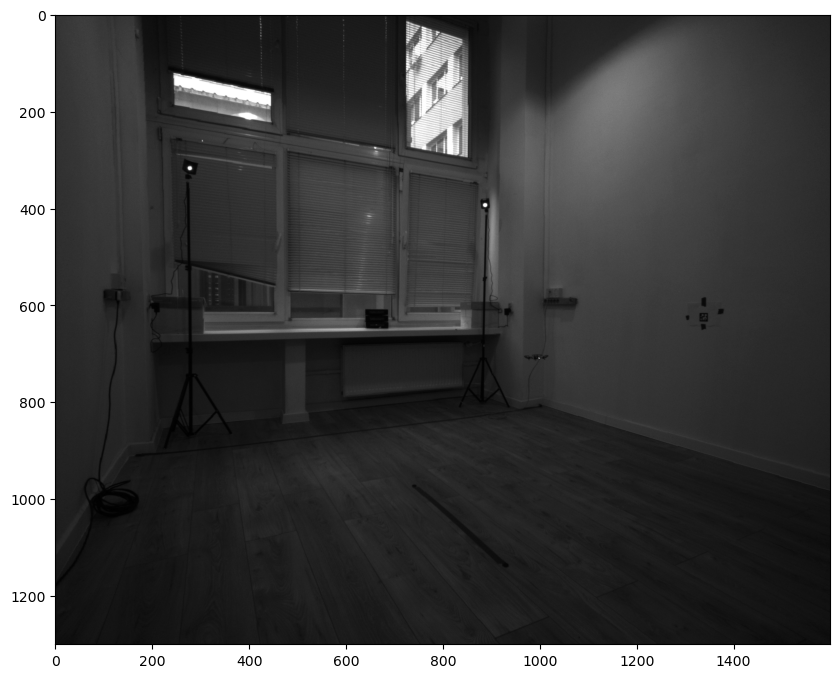

In [117]:
left, right = load_frames(100)
plt.figure(figsize=(10, 10))
plt.imshow(left, cmap="gray")

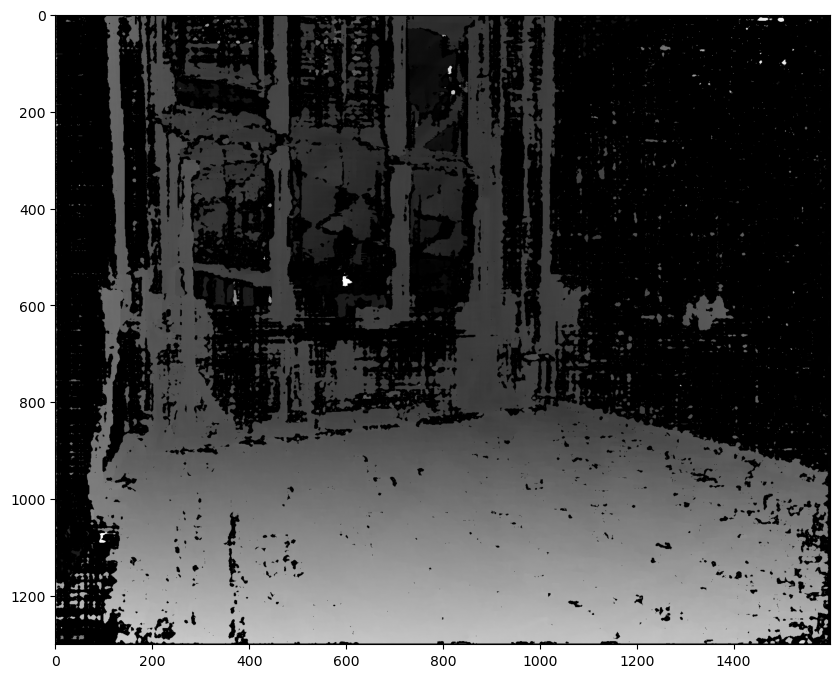

In [118]:
matcher = cv.cuda.createStereoSGM(0, 128, 10, 60, 10, cv.STEREO_SGBM_MODE_HH4)
filter = cv.cuda.createDisparityBilateralFilter(128, 3, 1)
#srleft = cv.resize(rleft, None, fx=0.5, fy=0.5, interpolation=cv.INTER_CUBIC)
#srright = cv.resize(rright, None, fx=0.5, fy=0.5, interpolation=cv.INTER_CUBIC)
left_gpu = cv.cuda.GpuMat(left)
right_gpu = cv.cuda.GpuMat(right)
disparity = matcher.compute(left_gpu, right_gpu)
disparity = filter.apply(disparity, left_gpu)
disp_normalized_gpu = cv.cuda.normalize(disparity, 0, 255, cv.NORM_MINMAX, cv.CV_8UC1)
disp_normalized = disp_normalized_gpu.download()
plt.figure(figsize=(10, 10))
plt.imshow(disp_normalized, cmap='gray')

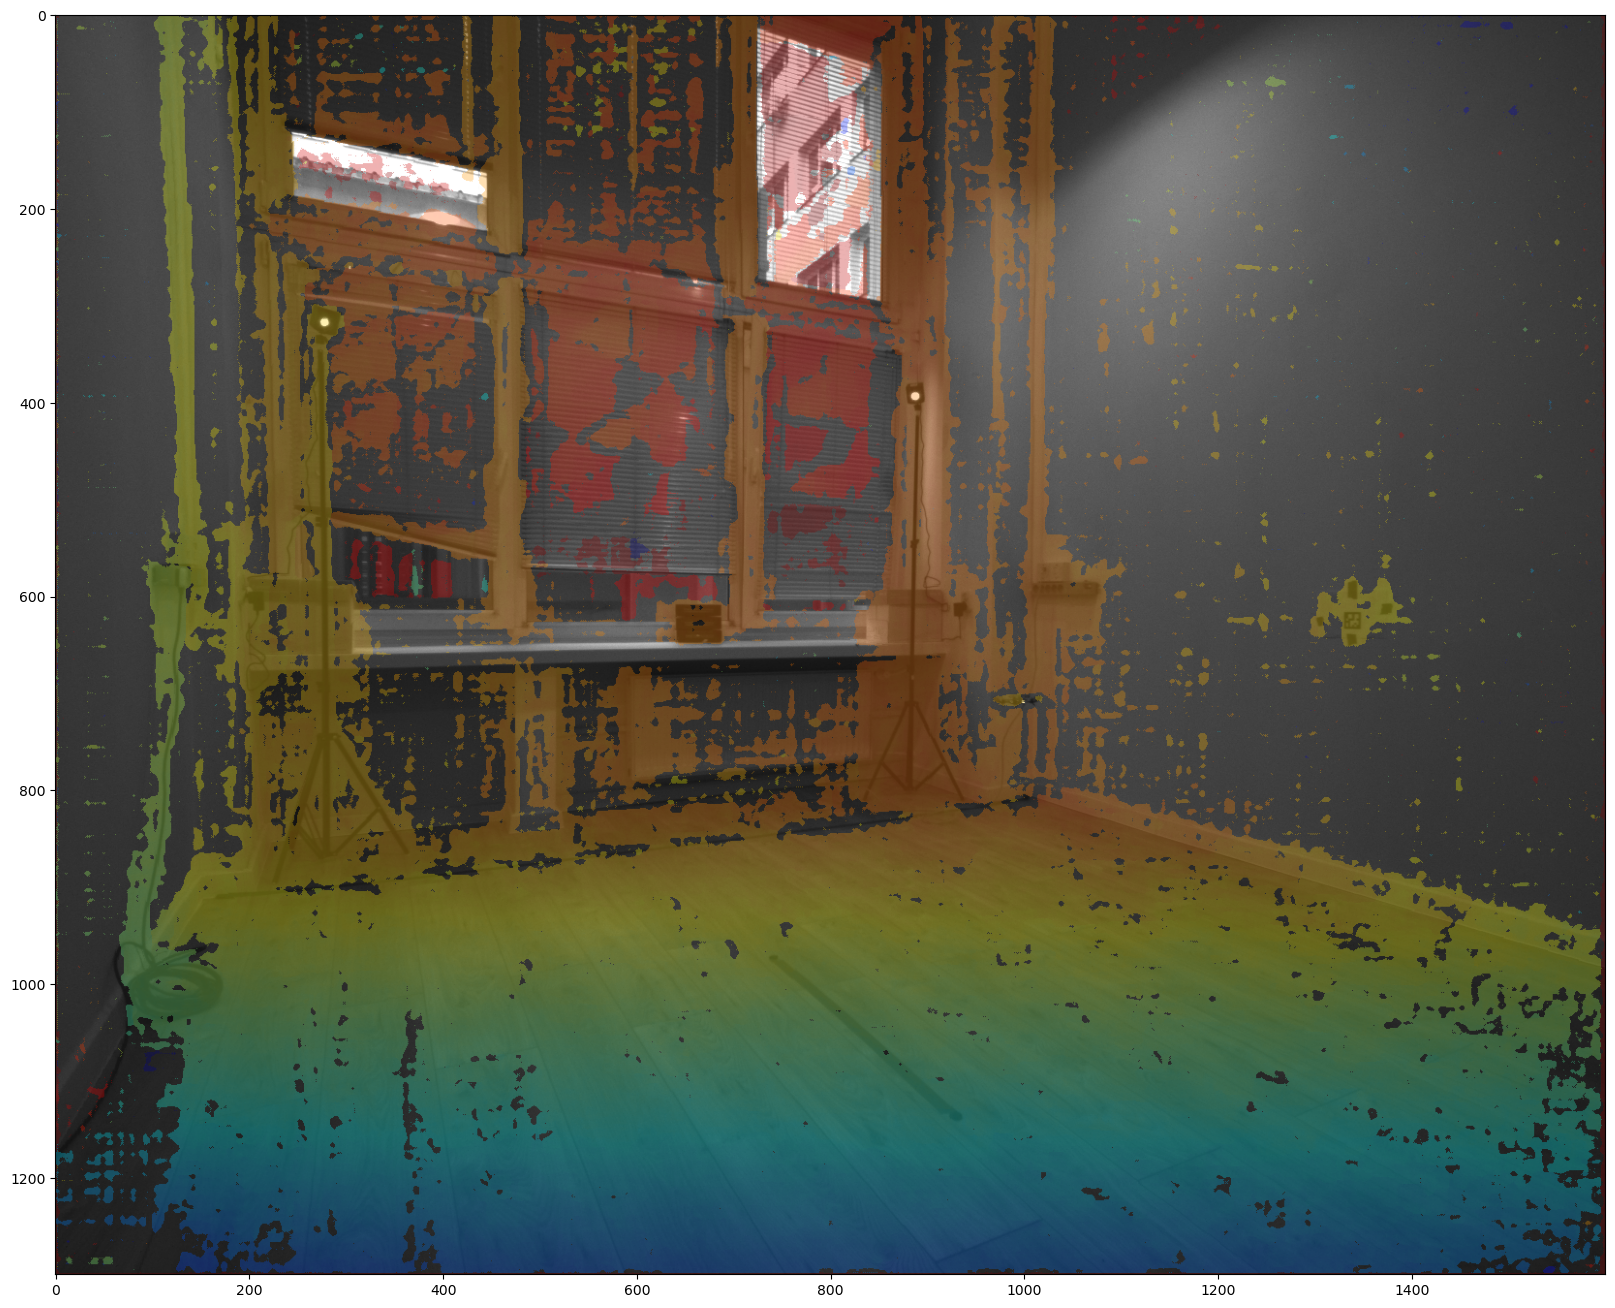

In [119]:
alpha = 0.3

mask = disp_normalized > 0
disp_color = cv.applyColorMap(disp_normalized, cv.COLORMAP_JET)
overlay = left.copy()
#overlay = cv.resize(overlay, None, fx=0.5, fy=0.5, interpolation=cv.INTER_CUBIC)
overlay = cv.cvtColor(overlay, cv.COLOR_GRAY2BGR)

overlay[mask] = cv.addWeighted(overlay[mask], 1 - alpha, disp_color[mask], alpha, 0)

plt.figure(figsize=(20, 20))
plt.imshow(overlay, cmap='gray')


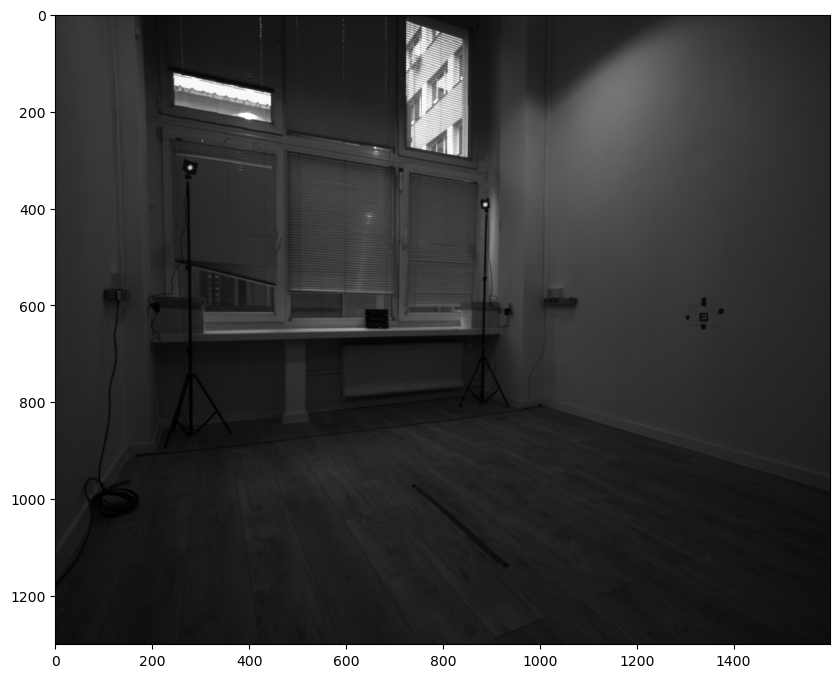

In [120]:
def average_frame(n: int = 200):
  frames = []
  for i in range(n):
    frames.append(load_frames(i)[0])
  return np.average(frames, 0)

avg_frame = average_frame()

plt.figure(figsize=(10, 10))
plt.imshow(average_frame(), cmap='gray')

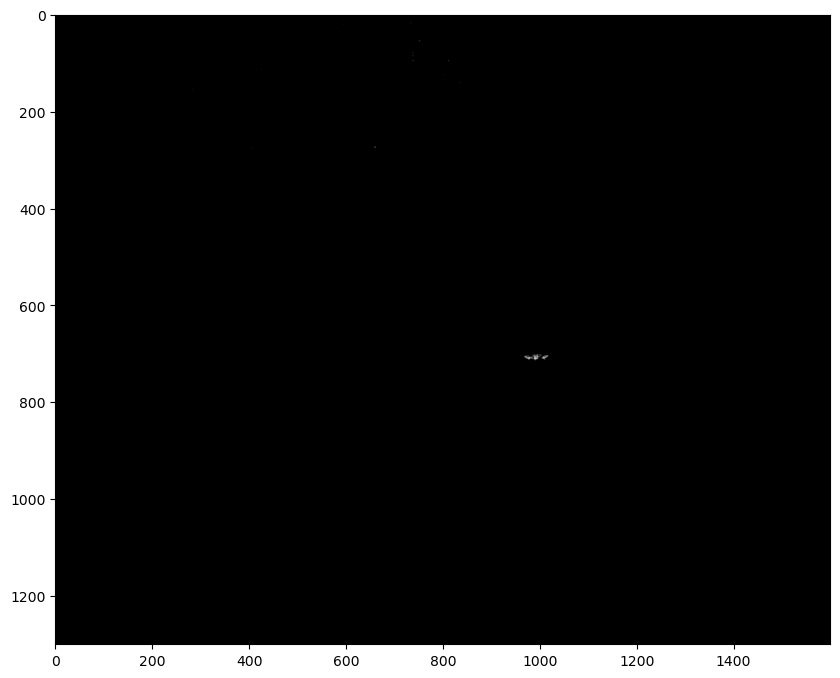

In [121]:
frame, frame2 = load_frames(100)
diff: np.ndarray = avg_frame - frame
diff[diff < 10] = 0
diff[350:450, 850:950] = 0
diff[300:400, 200:300] = 0
#diff = cv.GaussianBlur(diff, (0, 0), 5)
plt.figure(figsize=(10, 10))
plt.imshow(diff, cmap='gray')

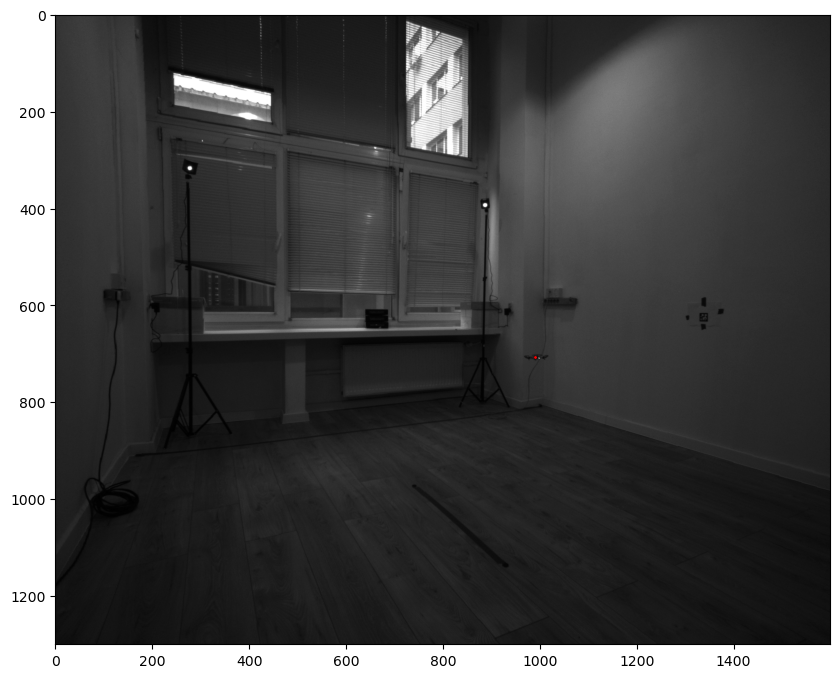

In [122]:
pixels = np.argwhere(diff != 0)
drone_y, drone_x = np.median(pixels, 0)
drone_y = int(drone_y)
drone_x = int(drone_x)

plt.figure(figsize=(10, 10))
plt.imshow(frame, cmap='gray')
plt.scatter(drone_x, drone_y, color='red', s=1)

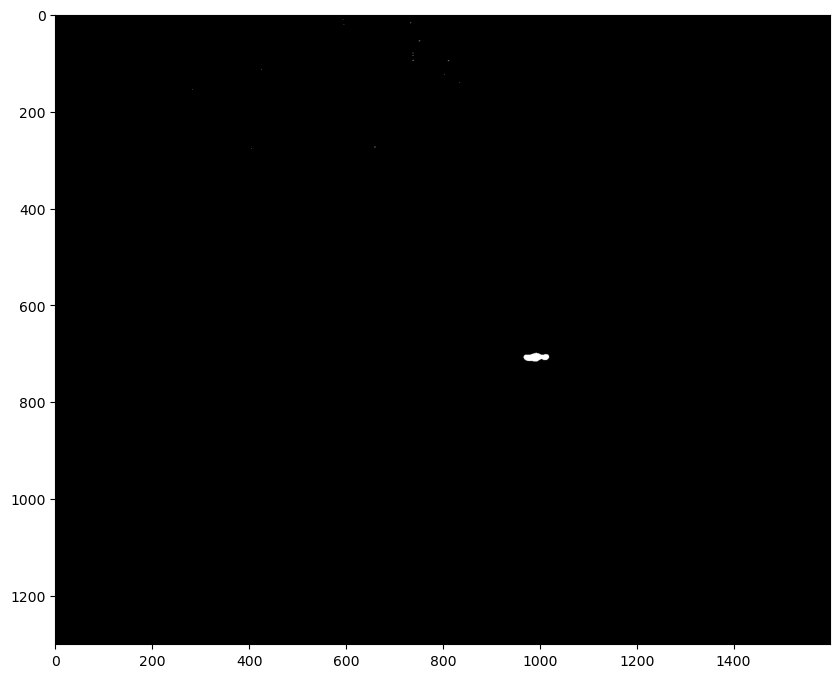

In [123]:
drone_mag_factor = 1.10

drone_patch = diff[drone_y-100:drone_y+100, drone_x-100:drone_x+100]
drone_patch = cv.resize(drone_patch, None, fx=drone_mag_factor, fy=drone_mag_factor, interpolation=cv.INTER_CUBIC)
drone_patch = cv.GaussianBlur(drone_patch, (0, 0), 5)
drone_patch = drone_patch[(drone_patch.shape[0]//2)-100:(drone_patch.shape[0]//2)+100, (drone_patch.shape[1]//2)-100:(drone_patch.shape[1]//2)+100]
diff_mag = diff.copy()
diff_mag[drone_y-100:drone_y+100, drone_x-100:drone_x+100] = drone_patch
diff_mag[diff_mag > 5] = 255
diff_mag[diff_mag <= 0] = 0
plt.figure(figsize=(10, 10))
plt.imshow(diff_mag, cmap='gray')

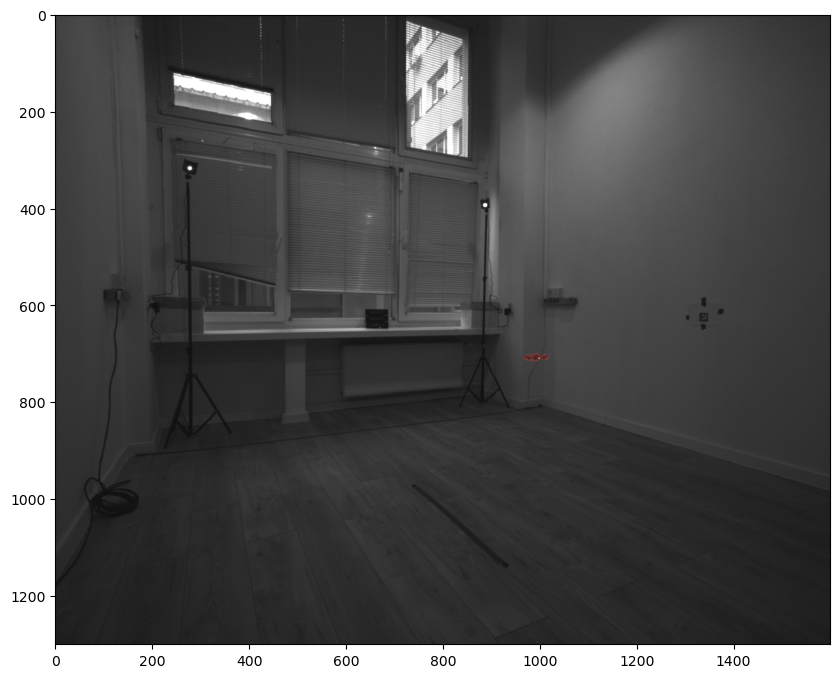

In [124]:
overlay = frame.copy()
diff_drone = diff_mag.astype(np.uint8)
diff_drone = cv.cvtColor(diff_drone, cv.COLOR_GRAY2BGR)
diff_drone[:, :, 1:3] = 0
overlay = cv.addWeighted(overlay, 1, diff_drone, 0.2, 0)
diff_drone = diff_drone[:, :, 0]

plt.figure(figsize=(10, 10))
plt.imshow(overlay)

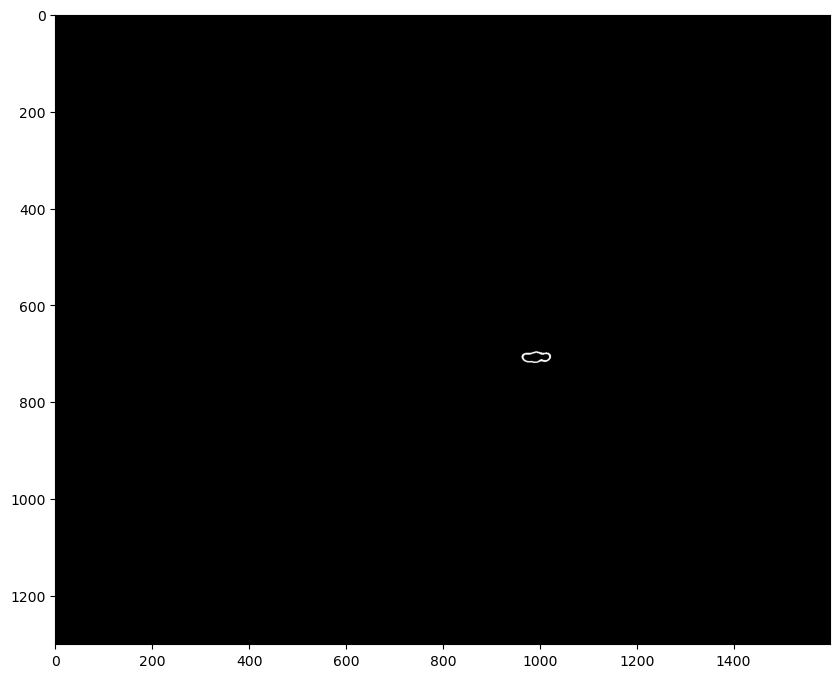

In [125]:
drone_mag_factor = 1.1

drone_patch = diff[drone_y-100:drone_y+100, drone_x-100:drone_x+100]
drone_patch = cv.resize(drone_patch, None, fx=drone_mag_factor, fy=drone_mag_factor, interpolation=cv.INTER_CUBIC)
drone_patch = cv.GaussianBlur(drone_patch, (0, 0), 5)
drone_patch = drone_patch[(drone_patch.shape[0]//2)-100:(drone_patch.shape[0]//2)+100, (drone_patch.shape[1]//2)-100:(drone_patch.shape[1]//2)+100]
diff_mag = diff.copy()
diff_mag[drone_y-100:drone_y+100, drone_x-100:drone_x+100] = drone_patch
diff_mag[diff_drone > 5] = 0
diff_mag[diff_mag > 2] = 255
plt.figure(figsize=(10, 10))
plt.imshow(diff_mag, cmap='gray')

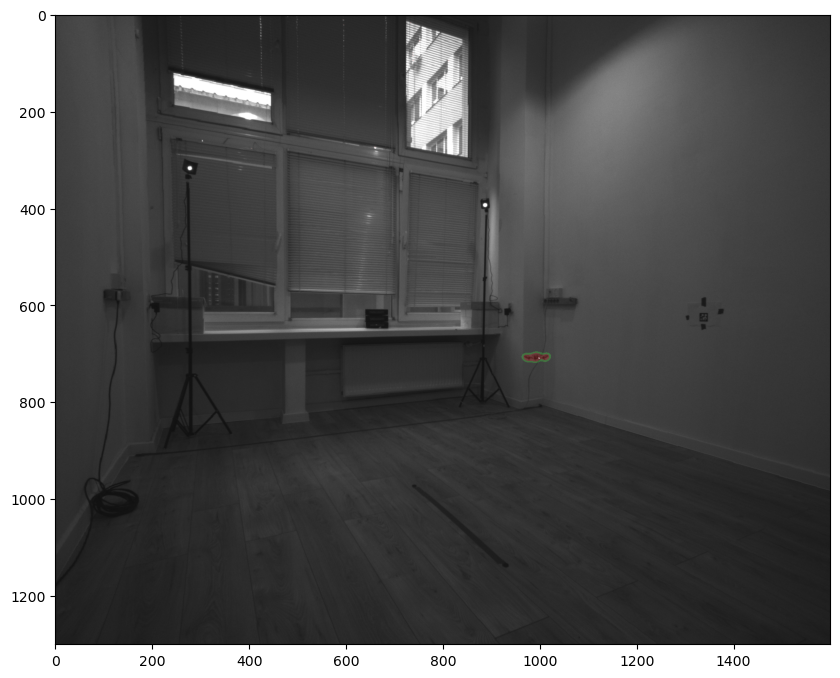

In [126]:
diff_outer = diff_mag.astype(np.uint8)
diff_outer = cv.cvtColor(diff_outer, cv.COLOR_GRAY2BGR)
diff_outer[:, :, (0, 2)] = 0
overlay2 = cv.addWeighted(overlay, 1, diff_outer, 0.2, 0)
diff_outer = diff_outer[:, :, 0]

plt.figure(figsize=(10, 10))
plt.imshow(overlay2)